In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Clone your repo into Colab
!rm -rf codsoft-projects
!git clone https://github.com/Priyadh1/codsoft-projects.git

# Show what is inside, so we can confirm the folder name
!ls codsoft-projects
!ls codsoft-projects/Task1_Titanic

train = pd.read_csv("codsoft-projects/Task1_Titanic/train.csv")
test = pd.read_csv("codsoft-projects/Task1_Titanic/test.csv")

print("Train:", train.shape)
print("Test:", test.shape)
train.head()

Cloning into 'codsoft-projects'...
remote: Enumerating objects: 38, done.
remote: Counting objects: 100% (38/38), done.
remote: Compressing objects: 100% (34/34), done.
remote: Total 38 (delta 9), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (38/38), 89.91 KiB | 5.29 MiB/s, done.
Resolving deltas: 100% (9/9), done.
README.md  Task1_Titanic
gender_submission.csv  test.csv		    titanic_model.pkl
index.html	       titanic_columns.pkl  titanic_predictions.csv
README.md	       titanic_model.js     train.csv
Train: (891, 12)
Test: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Age         177
Cabin       687
Embarked      2
dtype: int64

Overall survival rate: 38.4 %

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64

Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64


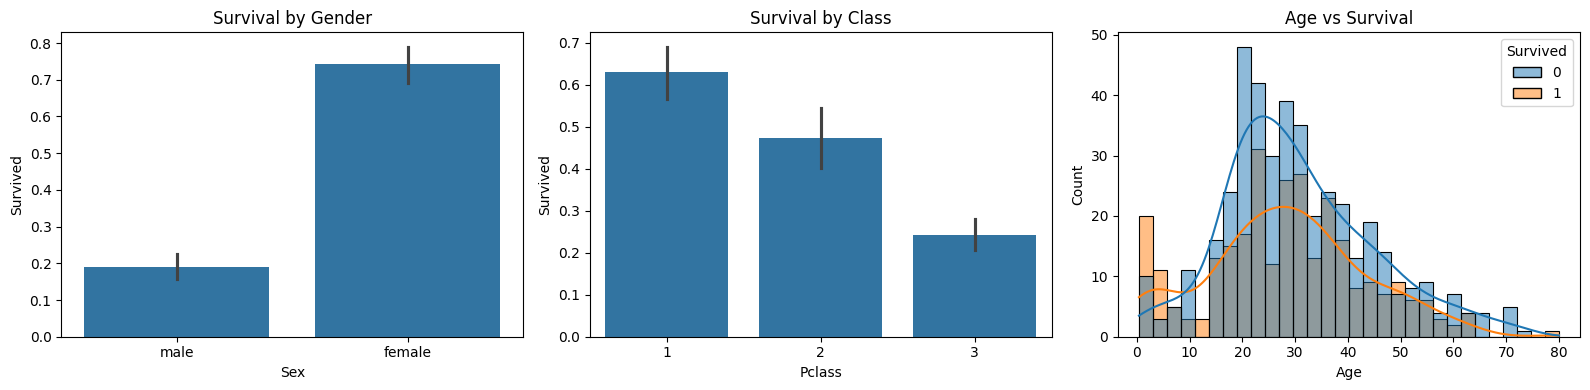

In [27]:
# 1. Missing values
missing = train.isnull().sum()
print(missing[missing > 0])
print()

# 2. Overall survival rate
print("Overall survival rate:", round(train["Survived"].mean() * 100, 1), "%")
print()

# 3. Survival rate by gender and by class
print(train.groupby("Sex")["Survived"].mean().round(3))
print()
print(train.groupby("Pclass")["Survived"].mean().round(3))

# 4. Charts
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(data=train, x="Sex", y="Survived", ax=ax[0])
ax[0].set_title("Survival by Gender")

sns.barplot(data=train, x="Pclass", y="Survived", ax=ax[1])
ax[1].set_title("Survival by Class")

sns.histplot(data=train, x="Age", hue="Survived", bins=30, kde=True, ax=ax[2])
ax[2].set_title("Age vs Survival")

plt.tight_layout()
plt.show()

In [28]:
#feature engineering
def engineer_features(df):
    df = df.copy()

    # 1. Title from the name (Mr, Mrs, Miss, Master, ...)
    df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
    df["Title"] = df["Title"].replace(
        ["Mlle", "Ms"], "Miss").replace("Mme", "Mrs")
    common = ["Mr", "Mrs", "Miss", "Master"]
    df["Title"] = df["Title"].where(df["Title"].isin(common), "Rare")

    # 2. Family features
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

    # 3. Cabin: did the passenger have a recorded cabin?
    df["HasCabin"] = df["Cabin"].notna().astype(int)

    # 4. Fill missing values
    df["Age"] = df["Age"].fillna(df.groupby("Title")["Age"].transform("median"))
    df["Embarked"] = df["Embarked"].fillna("S")
    df["Fare"] = df["Fare"].fillna(df["Fare"].median())

    return df

train_fe = engineer_features(train)
test_fe = engineer_features(test)

print(train_fe[["Name", "Title", "FamilySize", "IsAlone", "HasCabin", "Age"]].head(8))
print()
print("Missing values left:", train_fe[["Age", "Embarked", "Fare"]].isnull().sum().sum())
print()
print(train_fe.groupby("Title")["Survived"].agg(["count", "mean"]).round(3))

                                                Name   Title  FamilySize  \
0                            Braund, Mr. Owen Harris      Mr           2   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...     Mrs           2   
2                             Heikkinen, Miss. Laina    Miss           1   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)     Mrs           2   
4                           Allen, Mr. William Henry      Mr           1   
5                                   Moran, Mr. James      Mr           1   
6                            McCarthy, Mr. Timothy J      Mr           1   
7                     Palsson, Master. Gosta Leonard  Master           5   

   IsAlone  HasCabin   Age  
0        0         0  22.0  
1        0         1  38.0  
2        1         0  26.0  
3        0         1  35.0  
4        1         0  35.0  
5        1         0  30.0  
6        1         1  54.0  
7        0         0   2.0  

Missing values left: 0

        count   mean
Title   

In [29]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

# 1. Pick the features and turn text columns into numbers
features = ["Pclass", "Sex", "Age", "Fare", "Embarked",
            "Title", "FamilySize", "IsAlone", "HasCabin"]

X = pd.get_dummies(train_fe[features], columns=["Sex", "Embarked", "Title"], drop_first=True)
y = train_fe["Survived"]

# 2. Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Compare three models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    val_acc = accuracy_score(y_val, model.predict(X_val))
    cv_acc = cross_val_score(model, X, y, cv=5).mean()
    results.append([name, round(val_acc, 3), round(cv_acc, 3)])

results_df = pd.DataFrame(results, columns=["Model", "Validation Acc", "5-Fold CV Acc"])
print(results_df)
print()
print("Feature columns:", list(X.columns))

                 Model  Validation Acc  5-Fold CV Acc
0  Logistic Regression           0.821          0.824
1        Random Forest           0.821          0.828
2    Gradient Boosting           0.827          0.834

Feature columns: ['Pclass', 'Age', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


              precision    recall  f1-score   support

        Died       0.83      0.90      0.86       110
    Survived       0.82      0.71      0.76        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.82       179



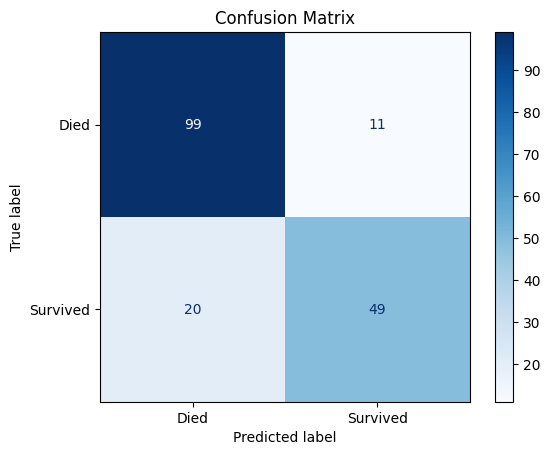

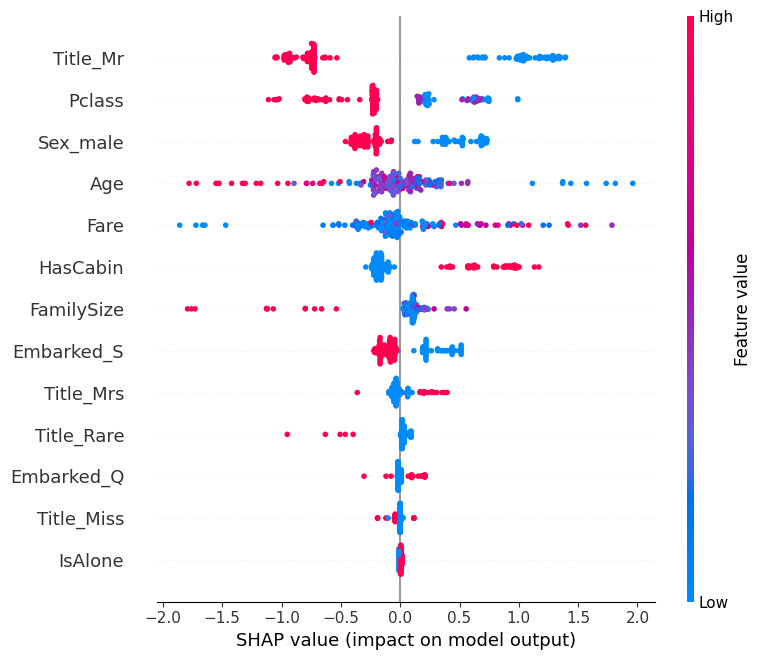

In [30]:
#shap explainability
!pip install shap -q

import shap
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Final model
final_model = GradientBoostingClassifier(random_state=42)
final_model.fit(X_train, y_train)
pred = final_model.predict(X_val)

# 2. Precision, recall, F1
print(classification_report(y_val, pred, target_names=["Died", "Survived"]))

# 3. Confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_val, pred),
                       display_labels=["Died", "Survived"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

# 4. SHAP: which features drive the predictions?
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_val)

shap.summary_plot(shap_values, X_val)

In [31]:
import joblib

# 1. Prepare the test data with the same columns as training
X_test = pd.get_dummies(test_fe[features], columns=["Sex", "Embarked", "Title"], drop_first=True)
X_test = X_test.reindex(columns=X.columns, fill_value=0)

# 2. Retrain on ALL training data, then predict on the test set
final_model = GradientBoostingClassifier(random_state=42)
final_model.fit(X, y)
test_pred = final_model.predict(X_test)

# 3. Save predictions
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_pred
})
submission.to_csv("titanic_predictions.csv", index=False)
print(submission["Survived"].value_counts())

# 4. Save the model and its column order, needed for the Streamlit app
joblib.dump(final_model, "titanic_model.pkl")
joblib.dump(list(X.columns), "titanic_columns.pkl")



Survived
0    272
1    146
Name: count, dtype: int64


['titanic_columns.pkl']

In [32]:
from google.colab import files

files.download("titanic_predictions.csv")
files.download("titanic_model.pkl")
files.download("titanic_columns.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
import json
from sklearn.preprocessing import StandardScaler

# 1. Scale the features, then train Logistic Regression on all training data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

lr = LogisticRegression(max_iter=1000)
lr.fit(X_scaled, y)
print("Training accuracy:", round(lr.score(X_scaled, y), 3))

# 2. Package everything the web page needs to reproduce the prediction
model_data = {
    "columns": list(X.columns),
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
    "coef": lr.coef_[0].tolist(),
    "intercept": float(lr.intercept_[0]),
}

# 3. Save as a .js file
with open("titanic_model.js", "w") as f:
    f.write("const MODEL = " + json.dumps(model_data, indent=2) + ";")

print(open("titanic_model.js").read()[:600])

# 4. Download it
from google.colab import files
files.download("titanic_model.js")

Training accuracy: 0.834
const MODEL = {
  "columns": [
    "Pclass",
    "Age",
    "Fare",
    "FamilySize",
    "IsAlone",
    "HasCabin",
    "Sex_male",
    "Embarked_Q",
    "Embarked_S",
    "Title_Miss",
    "Title_Mr",
    "Title_Mrs",
    "Title_Rare"
  ],
  "mean": [
    2.308641975308642,
    29.392446689113353,
    32.204207968574636,
    1.904601571268238,
    0.6026936026936027,
    0.22895622895622897,
    0.6475869809203143,
    0.08641975308641975,
    0.7250280583613917,
    0.20763187429854096,
    0.5802469135802469,
    0.1414141414141414,
    0.025813692480359147
  ],
  "scale": [
    0.83560193


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [34]:
#page design layout
%%writefile index.html
<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>The Last Voyage | Titanic Boarding Pass</title>
<link rel="preconnect" href="https://fonts.googleapis.com">
<link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;600&family=Playfair+Display:wght@600;700&display=swap" rel="stylesheet">
<style>
*{box-sizing:border-box}
:root{--gold:#c9a34e;--paper:#f3ead3;--ink:#1d1a14;--wine:#6e1b2a;--ok:#1e7a3c;--no:#b3202f}
html,body{margin:0}
body{min-height:100vh;color:#eae6da;font-family:"Inter",system-ui,sans-serif;overflow-x:hidden;
  background:radial-gradient(900px 500px at 75% -5%,#1b4a7d66,transparent),linear-gradient(#07162a,#0b2240)}
.sea{position:fixed;left:0;right:0;bottom:0;height:120px;pointer-events:none;opacity:.55;
  background:url("data:image/svg+xml;utf8,<svg xmlns='http://www.w3.org/2000/svg' width='720' height='120' viewBox='0 0 720 120'><path d='M0 60 Q180 10 360 60 T720 60 V120 H0Z' fill='%23123a66'/></svg>") repeat-x bottom;
  animation:drift 16s linear infinite}
.sea.two{height:90px;opacity:.4;animation-duration:10s;animation-direction:reverse}
@keyframes drift{to{background-position-x:720px}}
main{position:relative;z-index:1;max-width:1180px;margin:0 auto;padding:36px 20px 140px}
header{text-align:center;margin-bottom:30px}
.eyebrow{letter-spacing:.35em;font-size:12px;color:var(--gold);margin:0}
h1{font-family:"Playfair Display",Georgia,serif;font-size:clamp(42px,8vw,84px);font-weight:700;margin:8px 0;letter-spacing:.02em}
.lead{opacity:.7;max-width:560px;margin:0 auto}
.layout{display:grid;grid-template-columns:340px 1fr;gap:28px;align-items:start}
@media(max-width:900px){.layout{grid-template-columns:1fr}}
.panel{background:rgba(255,255,255,.06);border:1px solid rgba(255,255,255,.12);backdrop-filter:blur(12px);
  border-radius:18px;padding:22px;display:grid;gap:16px}
.lab{font-size:11px;letter-spacing:.18em;text-transform:uppercase;color:var(--gold);display:block;margin-bottom:6px}
input[type=text],input[type=number]{width:100%;padding:10px 12px;border-radius:10px;border:1px solid rgba(255,255,255,.18);
  background:rgba(0,0,0,.25);color:#fff;font-size:15px}
input[type=range]{width:100%;accent-color:var(--gold)}
.seg{display:flex;background:rgba(0,0,0,.25);border-radius:10px;padding:3px;gap:3px}
.seg button{flex:1;padding:9px 6px;border:none;border-radius:8px;background:transparent;color:#cfd6e2;cursor:pointer;font-size:14px}
.seg button.on{background:var(--gold);color:#1a1405;font-weight:600}
.two{display:grid;grid-template-columns:1fr 1fr;gap:10px}
.chk{display:flex;align-items:center;gap:8px;font-size:14px;cursor:pointer}
.chk input{accent-color:var(--gold)}
#go{padding:14px;border:none;border-radius:12px;background:linear-gradient(135deg,#e2bf6a,#b88a2e);color:#1a1405;
  font-size:15px;font-weight:700;letter-spacing:.14em;cursor:pointer}
#go:hover{filter:brightness(1.08)}

.stage{perspective:1400px}
.ticket{position:relative;display:grid;grid-template-columns:1fr 250px;background:var(--paper);color:var(--ink);
  border-radius:14px;box-shadow:0 30px 60px rgba(0,0,0,.5);transition:transform .15s ease-out;overflow:hidden}
.ticket::after{content:"";position:absolute;inset:0;pointer-events:none;mix-blend-mode:multiply;opacity:.9;
  background-image:url("data:image/svg+xml;utf8,<svg xmlns='http://www.w3.org/2000/svg' width='220' height='220'><filter id='n'><feTurbulence type='fractalNoise' baseFrequency='.85' numOctaves='2' stitchTiles='stitch'/><feColorMatrix values='0 0 0 0 .35 0 0 0 0 .25 0 0 0 0 .1 0 0 0 .18 0'/></filter><rect width='100%25' height='100%25' filter='url(%23n)'/></svg>")}
.bar{grid-column:1/-1;background:var(--wine);color:var(--paper);padding:12px 22px;display:flex;justify-content:space-between;
  font-family:Georgia,serif;letter-spacing:.14em;font-size:13px}
.main{padding:22px;display:grid;grid-template-columns:repeat(3,1fr);gap:20px 14px;align-content:start}
.wide{grid-column:1/-1}
.k{font-size:10px;letter-spacing:.2em;color:#8a7d62;display:block;margin-bottom:3px}
.val{font-family:"Playfair Display",Georgia,serif;font-size:18px;font-weight:600;word-break:break-word}
.val.big{font-size:34px}
.stub{border-left:2px dashed #a89c80;padding:22px 16px;text-align:center;position:relative;
  display:flex;flex-direction:column;align-items:center;gap:6px}
.stub::before,.stub::after{content:"";position:absolute;left:-11px;width:20px;height:20px;border-radius:50%;background:#0a1d36}
.stub::before{top:-10px}.stub::after{bottom:-10px}
.gauge{position:relative;width:150px;height:150px;margin-top:6px}
.gauge svg{width:100%;height:100%;transform:rotate(-90deg)}
.track{fill:none;stroke:#d8cfb6;stroke-width:9}
.arc{fill:none;stroke:var(--gold);stroke-width:9;stroke-linecap:round;stroke-dasharray:100;stroke-dashoffset:100;
  transition:stroke-dashoffset 1s ease-out,stroke .3s}
.pct{position:absolute;inset:0;display:grid;place-content:center;font:700 34px "Playfair Display",Georgia,serif}
.stamp{margin-top:8px;min-height:44px;border:5px solid;padding:4px 12px;font:700 21px Georgia,serif;letter-spacing:.12em;
  opacity:0;transform:rotate(-8deg);filter:url(#ink)}
.stamp.ok{color:var(--ok)}.stamp.no{color:var(--no)}
.stamp.hit{animation:hit .5s cubic-bezier(.2,1.4,.4,1) forwards}
@keyframes hit{0%{opacity:0;transform:scale(3) rotate(-22deg)}60%{opacity:1}100%{opacity:.9;transform:scale(1) rotate(-8deg)}}
.ticket.thud{animation:thud .35s ease-out}
@keyframes thud{0%{transform:none}30%{transform:translateY(6px) scale(.995)}100%{transform:none}}
.actions{display:flex;gap:10px;margin-top:16px;flex-wrap:wrap}
.ghost{padding:11px 18px;border-radius:10px;border:1px solid rgba(255,255,255,.25);background:rgba(255,255,255,.07);
  color:#fff;cursor:pointer;font-size:14px}
.ghost:hover:not(:disabled){background:rgba(255,255,255,.15)}
.ghost:disabled{opacity:.35;cursor:not-allowed}
.card{margin-top:18px;background:rgba(255,255,255,.06);border:1px solid rgba(255,255,255,.12);border-radius:16px;padding:18px}
.card h3{margin:0 0 12px;font:600 18px "Playfair Display",Georgia,serif}
.card small{opacity:.6;display:block;margin-top:10px}
.hidden{display:none}
.frow{display:grid;grid-template-columns:100px 1fr 46px;gap:10px;align-items:center;margin:8px 0;font-size:14px;opacity:.65}
.frow.me{opacity:1;color:var(--gold)}
.fbar{height:10px;background:rgba(255,255,255,.1);border-radius:6px;overflow:hidden}
.fbar i{display:block;height:100%;width:0;background:var(--gold);transition:width .9s ease-out}
.chip{display:inline-block;padding:6px 12px;margin:4px 6px 0 0;border-radius:999px;font-size:13px;background:rgba(255,255,255,.08)}
.chip.up{color:#8be0a4}.chip.down{color:#ff9aa5}
.note{margin-top:26px;font-size:12px;opacity:.55;text-align:center}
#toast{position:fixed;left:50%;bottom:26px;transform:translateX(-50%) translateY(20px);background:#fff;color:#111;
  padding:12px 18px;border-radius:10px;opacity:0;transition:.3s;z-index:10;max-width:90vw;font-size:14px}
#toast.show{opacity:1;transform:translateX(-50%)}
@media(max-width:620px){
  .ticket{grid-template-columns:1fr}.main{grid-template-columns:1fr 1fr}
  .stub{border-left:none;border-top:2px dashed #a89c80}.stub::before,.stub::after{display:none}
}
</style>
</head>
<body>
<svg width="0" height="0" style="position:absolute" aria-hidden="true">
  <filter id="ink"><feTurbulence type="fractalNoise" baseFrequency="0.9" numOctaves="2" result="n"/>
  <feDisplacementMap in="SourceGraphic" in2="n" scale="3"/></filter>
</svg>
<div class="sea"></div><div class="sea two"></div>

<main>
  <header>
    <p class="eyebrow">SOUTHAMPTON → NEW YORK · APRIL 1912</p>
    <h1>The Last Voyage</h1>
    <p class="lead">Fill in your details and watch the ticket update live. Then stamp it and see whether you would have made it.</p>
  </header>

  <div class="layout">
    <form class="panel" onsubmit="return false">
      <div><label class="lab" for="name">Passenger name</label>
        <input type="text" id="name" maxlength="26" placeholder="Your name"></div>
      <div><span class="lab">Gender</span>
        <div class="seg" data-key="sex"><button type="button" data-v="male" class="on">Male</button><button type="button" data-v="female">Female</button></div></div>
      <label class="chk" id="marriedRow"><input type="checkbox" id="married"> Married woman</label>
      <div><label class="lab" for="age">Age: <span id="ageOut">30</span></label>
        <input type="range" id="age" min="1" max="80" value="30"></div>
      <div><span class="lab">Ticket class</span>
        <div class="seg" data-key="pclass"><button type="button" data-v="1">1st</button><button type="button" data-v="2">2nd</button><button type="button" data-v="3" class="on">3rd</button></div></div>
      <div><span class="lab">Port of embarkation</span>
        <div class="seg" data-key="embarked"><button type="button" data-v="S" class="on">Southampton</button><button type="button" data-v="C">Cherbourg</button><button type="button" data-v="Q">Queenstown</button></div></div>
      <div><label class="lab" for="fare">Fare paid (GBP)</label><input type="number" id="fare" min="0" max="520" value="32"></div>
      <div class="two">
        <div><label class="lab" for="sibsp">Siblings / spouse</label><input type="number" id="sibsp" min="0" max="8" value="0"></div>
        <div><label class="lab" for="parch">Parents / children</label><input type="number" id="parch" min="0" max="6" value="0"></div>
      </div>
      <label class="chk"><input type="checkbox" id="cabin"> Has a private cabin</label>
      <button type="button" id="go">STAMP MY TICKET</button>
      <label class="chk"><input type="checkbox" id="sound"> Ocean sound</label>
    </form>

    <section class="stage" id="stage">
      <div class="ticket" id="ticket">
        <div class="bar"><span>THE LAST VOYAGE · BOARDING PASS</span><span id="t_no">No. 0000</span></div>
        <div class="main">
          <div class="wide"><span class="k">PASSENGER</span><div class="val big" id="t_name"></div></div>
          <div><span class="k">CLASS</span><div class="val" id="t_class"></div></div>
          <div><span class="k">AGE · GENDER</span><div class="val" id="t_agesex"></div></div>
          <div><span class="k">PARTY</span><div class="val" id="t_family"></div></div>
          <div><span class="k">EMBARKED</span><div class="val" id="t_port"></div></div>
          <div><span class="k">FARE</span><div class="val" id="t_fare"></div></div>
          <div><span class="k">ROUTE</span><div class="val">Southampton → New York</div></div>
        </div>
        <div class="stub">
          <span class="k">SURVIVAL CHANCE</span>
          <div class="gauge">
            <svg viewBox="0 0 120 120"><circle cx="60" cy="60" r="52" pathLength="100" class="track"/><circle id="ring" cx="60" cy="60" r="52" pathLength="100" class="arc"/></svg>
            <div class="pct" id="pct">?</div>
          </div>
          <div class="stamp" id="stamp"></div>
        </div>
      </div>

      <div class="actions">
        <button class="ghost" id="dl" disabled>⬇ Download ticket (PNG)</button>
        <button class="ghost" id="share" disabled>↗ Share my result</button>
      </div>

      <div class="card hidden" id="fate">
        <h3>Your fate by class</h3>
        <div class="frow" data-c="1"><span>First class</span><div class="fbar"><i></i></div><b>-</b></div>
        <div class="frow" data-c="2"><span>Second class</span><div class="fbar"><i></i></div><b>-</b></div>
        <div class="frow" data-c="3"><span>Third class</span><div class="fbar"><i></i></div><b>-</b></div>
        <small>Same passenger, different ticket class (with a typical fare for that class).</small>
      </div>

      <div class="card hidden" id="why">
        <h3>What shaped your result</h3>
        <div id="whyChips"></div>
        <small>▲ raises and ▼ lowers your survival chance compared with an average passenger.</small>
      </div>

      <p class="note">A simple machine learning model trained on 891 real passengers (about 82% accurate in testing). It finds patterns in history. It cannot judge real people.</p>
    </section>
  </div>
</main>
<div id="toast"></div>


Overwriting index.html


In [35]:
#logics, sound
%%writefile -a index.html
<script src="titanic_model.js"></script>
<script>
const $ = id => document.getElementById(id);
const S = {sex:"male", pclass:3, embarked:"S"};
let result = null, token = 0, audio = null;

const CLASS = {1:"First Class", 2:"Second Class", 3:"Third Class"};
const PORT = {S:"Southampton", C:"Cherbourg", Q:"Queenstown"};
const TYPICAL_FARE = {1:60, 2:15, 3:8};
const NAMES = {Pclass:"ticket class", Age:"your age", Fare:"fare paid", FamilySize:"family size",
  IsAlone:"travelling alone", HasCabin:"having a cabin", Sex_male:"being male",
  Embarked_Q:"boarding at Queenstown", Embarked_S:"boarding at Southampton",
  Title_Miss:"title Miss", Title_Mr:"title Mr", Title_Mrs:"title Mrs", Title_Rare:"a rare title"};

function num(id, def, lo, hi){
  let x = parseFloat($(id).value);
  if (isNaN(x)) x = def;
  return Math.min(hi, Math.max(lo, x));
}

function readForm(){
  return {
    name: $("name").value.trim() || "Your Name",
    sex: S.sex, pclass: S.pclass, embarked: S.embarked,
    age: Math.round(num("age", 30, 1, 80)),
    fare: num("fare", 32, 0, 520),
    sibsp: Math.round(num("sibsp", 0, 0, 8)),
    parch: Math.round(num("parch", 0, 0, 6)),
    cabin: $("cabin").checked,
    married: S.sex === "female" && $("married").checked
  };
}

// Same steps as the notebook: title, family size, one-hot columns, scaling, sigmoid
function predict(v){
  const title = v.sex === "male" ? (v.age < 13 ? "Master" : "Mr") : (v.married ? "Mrs" : "Miss");
  const fam = v.sibsp + v.parch + 1;
  const row = {};
  MODEL.columns.forEach(c => row[c] = 0);
  row.Pclass = v.pclass; row.Age = v.age; row.Fare = v.fare;
  row.FamilySize = fam; row.IsAlone = fam === 1 ? 1 : 0; row.HasCabin = v.cabin ? 1 : 0;
  if (v.sex === "male") row.Sex_male = 1;
  if (v.embarked === "Q") row.Embarked_Q = 1;
  if (v.embarked === "S") row.Embarked_S = 1;
  if (["Miss","Mr","Mrs","Rare"].includes(title)) row["Title_" + title] = 1;

  let z = MODEL.intercept;
  const contrib = [];
  MODEL.columns.forEach((c, i) => {
    const part = MODEL.coef[i] * (row[c] - MODEL.mean[i]) / MODEL.scale[i];
    z += part;
    contrib.push({name: NAMES[c] || c, val: part});
  });
  return {p: 1 / (1 + Math.exp(-z)), contrib};
}

function updateTicket(){
  const v = readForm();
  $("ageOut").textContent = v.age;
  $("t_name").textContent = v.name;
  $("t_class").textContent = CLASS[v.pclass];
  $("t_agesex").textContent = v.age + " · " + (v.sex === "male" ? "Male" : "Female");
  $("t_port").textContent = PORT[v.embarked];
  $("t_fare").textContent = "£" + v.fare.toFixed(2);
  const party = v.sibsp + v.parch + 1;
  $("t_family").textContent = party === 1 ? "Travelling alone" : "Party of " + party;
  const h = Array.from(v.name).reduce((a, c) => (a * 31 + c.charCodeAt(0)) >>> 0, 7);
  $("t_no").textContent = "No. " + (1000 + h % 9000);
  $("marriedRow").style.display = S.sex === "female" ? "flex" : "none";
}

function unstamp(){
  token++; result = null;
  $("stamp").className = "stamp"; $("stamp").textContent = "";
  $("pct").textContent = "?";
  $("ring").style.strokeDashoffset = 100;
  $("fate").classList.add("hidden"); $("why").classList.add("hidden");
  $("dl").disabled = true; $("share").disabled = true;
}

function changed(){ updateTicket(); if (result) unstamp(); }

function countUp(target, my){
  const t0 = performance.now(), dur = 900;
  (function step(t){
    if (my !== token) return;
    const k = Math.min(1, (t - t0) / dur);
    $("pct").textContent = Math.round(target * (1 - Math.pow(1 - k, 3))) + "%";
    if (k < 1) requestAnimationFrame(step);
  })(t0);
}

function stamp(){
  if (typeof MODEL === "undefined"){ toast("titanic_model.js was not found next to index.html"); return; }
  const v = readForm(), r = predict(v);
  const survived = r.p >= 0.5, pct = Math.round(r.p * 100);
  const my = ++token;
  result = {v, p: r.p, survived, pct};

  const ring = $("ring");
  ring.style.stroke = survived ? "var(--ok)" : "var(--no)";
  ring.style.strokeDashoffset = 100 - pct;
  countUp(pct, my);

  const st = $("stamp");
  st.className = "stamp";
  st.textContent = survived ? "SURVIVED" : "LOST AT SEA";
  setTimeout(() => {
    if (my !== token) return;
    st.className = "stamp hit " + (survived ? "ok" : "no");
    const tk = $("ticket"); tk.classList.remove("thud"); void tk.offsetWidth; tk.classList.add("thud");
  }, 750);

  [1, 2, 3].forEach(c => {
    const q = predict({...v, pclass: c, fare: TYPICAL_FARE[c]}).p;
    const rowEl = document.querySelector('.frow[data-c="' + c + '"]');
    rowEl.querySelector("i").style.width = Math.round(q * 100) + "%";
    rowEl.querySelector("b").textContent = Math.round(q * 100) + "%";
    rowEl.classList.toggle("me", c === v.pclass);
  });
  $("fate").classList.remove("hidden");

  const box = $("whyChips"); box.textContent = "";
  r.contrib.sort((a, b) => Math.abs(b.val) - Math.abs(a.val)).slice(0, 4).forEach(c => {
    const s = document.createElement("span");
    s.className = "chip " + (c.val > 0 ? "up" : "down");
    s.textContent = (c.val > 0 ? "▲ " : "▼ ") + c.name;
    box.appendChild(s);
  });
  $("why").classList.remove("hidden");

  $("dl").disabled = false; $("share").disabled = false;
}

// ---------- ticket as a PNG (drawn on a canvas) ----------
function drawTicketCanvas(){
  const W = 1200, H = 560, c = document.createElement("canvas");
  c.width = W; c.height = H;
  const g = c.getContext("2d"), v = result.v;
  g.fillStyle = "#f3ead3"; g.fillRect(0, 0, W, H);
  for (let i = 0; i < 9000; i++){
    g.fillStyle = "rgba(90,60,20," + (Math.random() * 0.05) + ")";
    g.fillRect(Math.random() * W, Math.random() * H, 2, 2);
  }
  g.fillStyle = "#6e1b2a"; g.fillRect(0, 0, W, 76);
  g.fillStyle = "#f3ead3"; g.textBaseline = "middle"; g.font = "600 26px Georgia, serif";
  g.textAlign = "left"; g.fillText("THE LAST VOYAGE  ·  BOARDING PASS", 40, 38);
  g.textAlign = "right"; g.fillText($("t_no").textContent, 1160, 38);
  g.textAlign = "left"; g.textBaseline = "alphabetic";

  const label = (t, x, y) => { g.fillStyle = "#8a7d62"; g.font = "600 17px Georgia, serif"; g.fillText(t, x, y); };
  const value = (t, x, y, s = 32) => { g.fillStyle = "#1d1a14"; g.font = "600 " + s + "px Georgia, serif"; g.fillText(t, x, y); };
  label("PASSENGER", 40, 130); value(v.name, 40, 182, 52);
  label("CLASS", 40, 260);       value(CLASS[v.pclass], 40, 300);
  label("AGE · GENDER", 330, 260); value(v.age + " · " + (v.sex === "male" ? "Male" : "Female"), 330, 300);
  label("PARTY", 570, 260);      value($("t_family").textContent, 570, 300, 28);
  label("EMBARKED", 40, 380);    value(PORT[v.embarked], 40, 420);
  label("FARE", 330, 380);       value("£" + v.fare.toFixed(2), 330, 420);
  label("ROUTE", 570, 380);      value("Southampton → New York", 570, 420, 26);

  g.setLineDash([10, 8]); g.strokeStyle = "#9a8f78"; g.lineWidth = 3;
  g.beginPath(); g.moveTo(830, 100); g.lineTo(830, 540); g.stroke(); g.setLineDash([]);

  g.textAlign = "center";
  g.fillStyle = "#8a7d62"; g.font = "600 17px Georgia, serif"; g.fillText("SURVIVAL CHANCE", 1015, 140);
  g.fillStyle = result.survived ? "#1e7a3c" : "#b3202f";
  g.font = "700 120px Georgia, serif"; g.fillText(result.pct + "%", 1015, 270);

  g.save(); g.translate(1015, 400); g.rotate(-0.14);
  g.strokeStyle = g.fillStyle; g.lineWidth = 8; g.globalAlpha = 0.9;
  g.strokeRect(-150, -42, 300, 84);
  g.font = "700 38px Georgia, serif"; g.textBaseline = "middle";
  g.fillText(result.survived ? "SURVIVED" : "LOST AT SEA", 0, 2);
  g.restore();

  g.textAlign = "left"; g.globalAlpha = 1; g.fillStyle = "#8a7d62"; g.font = "italic 17px Georgia, serif";
  g.fillText("Predicted by a machine learning model trained on 891 real passengers", 40, 525);
  return c;
}

function downloadPng(blob){
  const a = document.createElement("a");
  a.href = URL.createObjectURL(blob);
  a.download = "my-last-voyage-ticket.png";
  document.body.appendChild(a); a.click(); a.remove();
}

function caption(){
  return "I just checked my fate on the Titanic: " +
    (result.survived ? "I would have SURVIVED" : "I would NOT have survived") +
    " (" + result.pct + "% survival chance) according to a machine learning model I built on 891 real passengers. Try yours: " +
    location.href + " #codsoft #datascience #machinelearning";
}

async function shareResult(){
  const blob = await new Promise(r => drawTicketCanvas().toBlob(r, "image/png"));
  const file = new File([blob], "my-last-voyage-ticket.png", {type: "image/png"});
  const text = caption();
  if (navigator.canShare && navigator.canShare({files: [file]})){
    try { await navigator.share({files: [file], text, title: "The Last Voyage"}); return; }
    catch(e){ if (e.name === "AbortError") return; }
  }
  downloadPng(blob);
  try { await navigator.clipboard.writeText(text); toast("Image saved and caption copied. Paste it into your LinkedIn post."); }
  catch(e){ toast("Image saved. Write your own caption with #codsoft."); }
}

let toastTimer;
function toast(msg){
  const t = $("toast"); t.textContent = msg; t.classList.add("show");
  clearTimeout(toastTimer); toastTimer = setTimeout(() => t.classList.remove("show"), 4000);
}

// ---------- ocean sound made in the browser (no audio file) ----------
function toggleSound(on){
  if (on){
    if (!audio){
      const ctx = new (window.AudioContext || window.webkitAudioContext)();
      const buf = ctx.createBuffer(1, ctx.sampleRate * 3, ctx.sampleRate);
      const d = buf.getChannelData(0); let last = 0;
      for (let i = 0; i < d.length; i++){ const w = Math.random() * 2 - 1; last = (last + 0.02 * w) / 1.02; d[i] = last * 3.5; }
      const src = ctx.createBufferSource(); src.buffer = buf; src.loop = true;
      const lp = ctx.createBiquadFilter(); lp.type = "lowpass"; lp.frequency.value = 500;
      const gain = ctx.createGain(); gain.gain.value = 0.15;
      const lfo = ctx.createOscillator(); lfo.frequency.value = 0.12;
      const lfoGain = ctx.createGain(); lfoGain.gain.value = 0.1;
      lfo.connect(lfoGain); lfoGain.connect(gain.gain);
      src.connect(lp); lp.connect(gain); gain.connect(ctx.destination);
      src.start(); lfo.start();
      audio = {ctx};
    }
    audio.ctx.resume();
  } else if (audio){ audio.ctx.suspend(); }
}

// ---------- wiring ----------
document.querySelectorAll(".seg").forEach(seg => {
  seg.addEventListener("click", e => {
    const b = e.target.closest("button"); if (!b) return;
    seg.querySelectorAll("button").forEach(x => x.classList.remove("on"));
    b.classList.add("on");
    const k = seg.dataset.key;
    S[k] = k === "pclass" ? Number(b.dataset.v) : b.dataset.v;
    changed();
  });
});
["name","age","fare","sibsp","parch","cabin","married"].forEach(id => $(id).addEventListener("input", changed));
$("go").addEventListener("click", stamp);
$("dl").addEventListener("click", async () => {
  const blob = await new Promise(r => drawTicketCanvas().toBlob(r, "image/png")); downloadPng(blob);
});
$("share").addEventListener("click", shareResult);
$("sound").addEventListener("change", e => toggleSound(e.target.checked));

// 3D tilt on the ticket
const tk = $("ticket"), stage = $("stage");
stage.addEventListener("mousemove", e => {
  const r = tk.getBoundingClientRect();
  const x = (e.clientX - r.left) / r.width - 0.5, y = (e.clientY - r.top) / r.height - 0.5;
  tk.style.transform = "rotateY(" + (x * 8) + "deg) rotateX(" + (-y * 8) + "deg)";
});
stage.addEventListener("mouseleave", () => { tk.style.transform = ""; });

updateTicket();
</script>
</body>
</html>

Appending to index.html


website link:https://priyadh1.github.io/codsoft-projects/Task1_Titanic/